# 07 · Streaming spikes in real time

So far every run has been **batch**: you set up inputs, `hw.run(...)`, then read the results *after*
it finishes. SpiNNaker2 can also stream spikes **live**, while the simulation runs — feeding inputs
in and reading activity out in real time. That's what enables closed-loop experiments, live
visualisation, and reacting to the network as it computes.

This notebook explains the two streaming apps, then builds a small **runnable** closed loop that uses
both. The transport model underneath — how spikes are packetized and moved between chip and host —
is documented in
[Data Streaming](https://spinnaker2.gitlab.io/py-spinnaker2/user_guide/data-streaming.html).

**By the end you'll know:**

- the two streaming apps — **SpikeReplicator** (host → chip) and **GatherAndStream** (chip → host),
- how each one is configured, and the key caveats to keep in mind,
- how to wire them into a live closed loop and read the streamed spikes back.

> **Warning**
>
> **Streaming requires a real SpiNNaker2 board.** Unlike the rest of these tutorials, it can't fall back to the Brian2 simulator. The two small `EventSource` / callback cells are plain Python and run anywhere, but the cells that build and run the network (from *"Putting it together"* onward) **only execute on hardware** — without board access you can still read them, but not execute.

## 1. Two apps, two directions

Streaming is built from two applications that run *alongside* your network — one per
direction. Data flows left → right in both rows below; each piece is tagged with where it lives:

```
stream IN    [host] event source  ──▶  [chip] SpikeReplicator  ──▶  [chip] your populations

stream OUT   [chip] your populations  ──▶  [chip] GatherAndStream  ──▶  [host] callback
```

The two `[host]` pieces are small bits of Python **you write** — they're how your code plugs into the stream:

- **event source** — an object with a `next()` method that returns the spike IDs to inject *right now*.
  SpikeReplicator polls it continuously. (You'll write a small `EventSource` class in the SR section below.)
- **callback** — a function GatherAndStream calls each time spikes arrive from the chip, handing you a
  `{timestep: [neuron_id, ...]}` dict to visualise, log, or react to. (Written in the GAS section below.)

| App | Direction | Its input | Use it for |
|-----|-----------|-----------|------------|
| **SpikeReplicator (SR)** | host → chip | a host event source (your `next()`) | injecting live inputs |
| **GatherAndStream (GAS)** | chip → host | spikes from the populations you connect to it | live monitoring / feedback |

Both apps are ordinary [`Population`](https://spinnaker2.gitlab.io/py-spinnaker2/api_reference/snn-api.html#spinnaker2.snn.Population)s of a special neuron model ([`"spike_replicator"`](https://spinnaker2.gitlab.io/py-spinnaker2/api_reference/neuron-models.html#spike-replicator-spike_replicator) / [`"gather_and_stream"`](https://spinnaker2.gitlab.io/py-spinnaker2/api_reference/neuron-models.html#gather-and-stream-gas))
— you build and `add` them just like any other population, as the demo below shows.

## 2. Streaming in: `SpikeReplicator`

SR injects host spikes onto the chip. You give it an **event source** — any object with a `next()`
method. There's no base class to subclass: SR just calls `.next()` on whatever you pass as its
`spike_source`, so a small class like the one below is enough.

SR polls `next()` from a host thread that runs *as fast as it can* — **not** locked to the simulation
clock — and injects whatever spike IDs come back. So each call asks "what should fire *right now*?",
and **event source**  itself controls the rate (via a per-poll probability, a small sleep, or by reading from
a real-time queue). Return `[]` when nothing should fire.

Here is the simplest event source that satisfies it — it fires one input neuron now and then:

In [1]:
import random
import time


class EventSource:
    """Fires input neuron 0 at random (~1 poll in 10) and records when, so we can plot the input later.

    SR polls next() as fast as it can, so we pace it here to one poll per 1 ms tick (default on-chip timestep length).
    We aim at an absolute deadline instead of sleep(0.001): sleep is only a floor,
    so per-poll overhead would otherwise pile up and drift behind the chip clock.
    Deadlines self-correct — a slow poll is followed by a shorter sleep."""

    def __init__(self, p=0.1, seed=16):
        self.p = p
        self.rng = random.Random(seed)
        self.timestep = 1  # SR replicates each incoming spike in the next timestep
        self.injected = []  # poll indices (≈ time steps) when we injected
        self._deadline = None

    def next(self):  # SR calls this repeatedly; return the IDs to fire now
        now = time.perf_counter()
        if self._deadline is None:
            self._deadline = now
        self._deadline += 0.001  # next tick, 1 ms later
        if self._deadline > now:
            time.sleep(self._deadline - now)
        ids = [0] if self.rng.random() < self.p else []
        if ids:
            self.injected.append(self.timestep)
        self.timestep += 1
        return ids


# What SR sees over 10 successive polls (neuron 0 fires on ~1 poll in 10):
src = EventSource()
print([src.next() for _ in range(10)])

[[], [], [], [], [], [], [], [], [0], []]


Each entry is one poll of `next()`, returning the neuron IDs to inject at that moment — here neuron 0
fires on roughly one poll in ten. SR injects exactly those. Your **event source** is also where all the
raw-data-to-spike-ID work lives: reading raw events (from a sensor, file, or model), dropping the ones
you don't want, and mapping the rest to the integer neuron IDs your network uses. SR does none of that
— it just injects whatever IDs you return.

Because SR polls `next()` in a tight loop **on its own thread**, an **event source** must:

- **return fast** — never block or wait for the next event; when nothing fires, return `[]` (or
  `None`), like `EventSource` does. Stalling in `next()` stalls injection.
- **set its own rate** — the loop is free-running and *not* tied to the simulation clock, so the source
  decides how often spikes go out: a per-poll probability, paced sleeps, or blocking-free reads from a
  real-time queue. Pace against *absolute deadlines* (as `EventSource` does), not a fixed `sleep`:
  sleep is only a floor, so per-poll overhead otherwise accumulates into drift against the chip clock.
- **be thread-safe** — if another thread produces your events, guard the data `next()` reads, since it
  runs on SR's thread, not your main one.

SR also requires **C2C routing** — call `set_routing_type("C2C")` before the run.

The runnable demo further down wires this same `EventSource` into a LIF population and runs it on the
board.

## 3. Streaming out: `GatherAndStream`

**GatherAndStream** is a 1-neuron population with a
**callback** that fires whenever spikes arrive from the chip. You connect the neurons you want to watch
to it — receiver id, weight and delay must all be `0`. Two parameters control the bandwidth/latency
trade-off:

- **`timewindow`** — send every step (`1`) or batch N steps (larger = less overhead, more latency).
- **`sample_only`** — capture all spikes within each window (`False`), or just those at window boundaries (`True`).

Underneath, GAS keeps **two buffers**. Incoming spikes accumulate in the write buffer; at each
window boundary the two swap atomically, and the streamer sends whatever is now in the read buffer
while fresh spikes land in the other one. That swap is what `timewindow` sizes, and it's why a
larger window costs latency rather than spikes.

With `timewindow = 4`, the two `sample_only` settings differ like this:

```
                 window 0          window 1          window 2
ticks:      0   1   2   3    |  4   5   6   7   |  8   9  10  11
spikes:    ***  **  *  ***   | **   *  ***  *   | **   *   *  ...

sample_only = False   accumulate ─────────────▶ send all 4 ticks
sample_only = True    keep tick 0, drop 1-3 ──▶ send tick 0 only
```

`False` captures everything, one transfer per window instead of per tick. `True` keeps only the
boundary tick, cutting bandwidth by roughly a factor of `timewindow` — useful when firing rates are
high enough that whatever consumes the stream can't keep up.

So the two parameters trade **bandwidth** against **temporal resolution**: `timewindow=1,
sample_only=False` is full fidelity and the most traffic; raising `timewindow` batches transfers
without losing spikes; adding `sample_only=True` drops to sparse sampling. Start at full fidelity
and back off only if the stream or its consumer becomes the bottleneck.

Notes:

- The callback receives **global** neuron IDs; convert them to population-relative IDs with
  `graph.decode_spike_key(key)` or, in bulk, `graph.relative_from_absolute_ids(net, spikes)`.
- **Liveness** — GAS heartbeats even when idle, so an empty callback dict just means "no spikes this
  window"; *no* packets at all means the run died and the host times out.
- GAS is for **live monitoring**, not guaranteed lossless recording (use `record=[...]` for that).

The **callback** itself is just a function. GAS hands it `{timestep: [neuron_id, ...]}`; a common pattern is
to invert that into `{neuron_id: [timestep, ...]}` so you can analyse each neuron's spike train
afterwards — the demo below reuses exactly this one:

In [2]:
streamed = {}  # {neuron_id: [timestep, ...]}, filled during the run


def callback(spikes):  # GAS calls this each time spikes arrive: {timestep: [id, ...]}
    for timestep, ids in spikes.items():
        for nid in ids:
            streamed.setdefault(nid, []).append(timestep)


# Illustrate with two windows of fake data (on hardware, GAS supplies these live):
callback({3: [0, 1]})
callback({7: [0]})

print(streamed)
streamed.clear()

{0: [3, 7], 1: [3]}


## 4. Putting it together: a runnable closed loop

The cells below build the smallest complete loop and run it on the board, reusing the `EventSource` and
`callback` from above:

```
EventSource ──▶ SpikeReplicator ──▶ LIF neuron ──▶ GatherAndStream ──▶ callback
```

Spikes flow in *and* out of the same live run — `SR` injects the `EventSource` input, `GAS` streams the LIF
response straight back to the `callback`. Each spike the `EventSource` injects drives the LIF over its
threshold, so the LIF answers with a spike of its own. Because the input fires at random (~1 poll in 10),
these responses land at irregular times — expect a handful of LIF spikes across the 50 steps, not one
at a fixed interval.

> **Note**
>
> For a much larger example (a clustered recurrent network driven by mixed pattern + noise input), see <a href="https://spinnaker2.gitlab.io/py-spinnaker2/examples/streaming_pipeline.html">Bidirectional streaming pipeline</a>.

In [ ]:
from spinnaker2 import snn, hardware
from spinnaker2.experiment_backends.backend_settings import set_routing_type

set_routing_type("C2C")  # SpikeReplicator requires C2C routing
hw = hardware.SpiNNcloud48NodeBoard()

INFO:     Path to spinnaker configuration directory found in global config path /etc/opt/spinnaker/SPINNAKER_CONFIG_PATH


In [4]:
event_source = EventSource()

sr = snn.Population(size=1, neuron_model="spike_replicator", params={"spike_source": event_source}, name="sr")

lif = snn.Population(
    size=1,
    neuron_model="lif",
    params={"threshold": 1.0, "alpha_decay": 0.9, "v_reset": 0.0, "reset": "reset_to_v_reset"},
    name="lif",
    record=["v"],  # record the membrane trace for the plot
)

gas = snn.Population(
    size=1,
    neuron_model="gather_and_stream",
    params={"callback": callback, "timewindow": 1, "sample_only": False},
    name="gas",
)

net = snn.Network("streaming_demo")

net.add(
    sr,
    lif,
    gas,
    snn.Projection(sr, lif, connections=[[0, 0, 2, 0]]),  # input -> LIF, weight 2 > threshold 1
    snn.Projection(lif, gas, connections=[[0, 0, 0, 0]]),  # LIF -> GAS: ids/weight/delay all 0
)

print(f"{net.name} network built")

streaming_demo network built


In [5]:
timesteps = 50
hw.run(net, timesteps, debug=True)  # live run: SR streams spikes in, GAS streams them back out

Number of cores needed: 3
Number of available cores: 148
Sim duration: 0.060000000000000005 s


Duration recording: 0.0008380413055419922


In [6]:
from spinnaker2.graph import relative_from_absolute_ids

# The callback saw global neuron IDs; regroup them per population, relative to each population.
relative = relative_from_absolute_ids(net, streamed)
print("spikes streamed back from 'lif':")
print(relative.get("lif", {}))

spikes streamed back from 'lif':
{0: [10, 22, 35, 44, 47]}


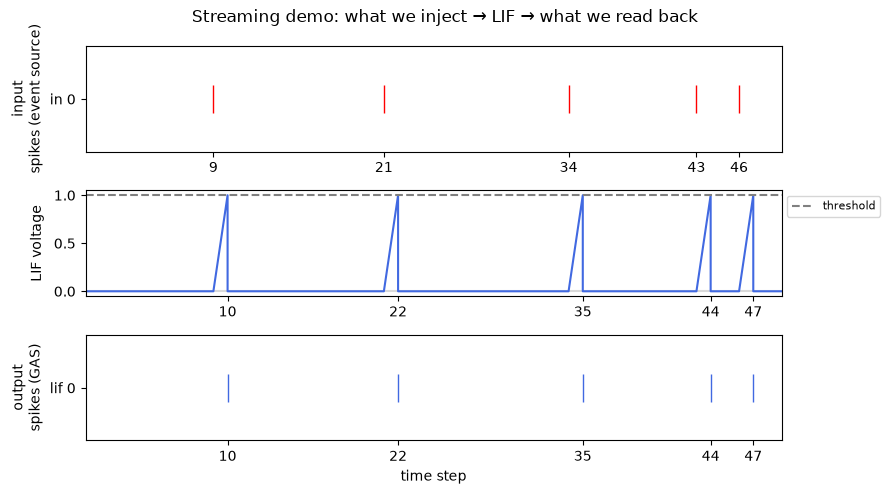

In [7]:
import matplotlib.pyplot as plt
from spinnaker2 import helpers

voltages = lif.get_voltages()
out_idx, out_t = helpers.spike_times_dict_to_arrays(relative.get("lif", {}))  # streamed output

corr_times, corr_voltage = helpers.get_corrected_voltage_trace(
    voltages[0],
    out_t,
    population_params={"threshold": 1.0, "alpha_decay": 0.9, "v_reset": 0.0, "reset": "reset_to_v_reset"},
)

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(9, 5))

# what we streamed in (host EventSource; poll index ≈ time step)
ax1.plot(event_source.injected, [0] * len(event_source.injected), "|", ms=20, c="red")
ax1.set_ylabel("input\nspikes (event source)")
ax1.set_yticks([0])
ax1.set_yticklabels(["in 0"])
ax1.set_ylim(-0.5, 0.5)
ax1.set_xticks(event_source.injected)
ax1.set_xlim(0, timesteps - 1)

# LIF membrane voltage
ax2.plot(corr_times, corr_voltage, color="royalblue")
ax2.axhline(lif.params["threshold"], ls="--", c="0.5", label="threshold")
ax2.axhline(0, ls="-", c="0.85", zorder=0)
ax2.set_ylabel("LIF voltage")
ax2.set_xlim(0, timesteps - 1)
ax2.legend(loc="upper left", bbox_to_anchor=(1, 1), fontsize=8)
ax2.set_xticks(out_t)

# what we read back out (streamed by GAS)
ax3.plot(out_t, out_idx, "|", ms=20, color="royalblue")
ax3.set_ylabel("output\nspikes (GAS)")
ax3.set_yticks([0])
ax3.set_yticklabels(["lif 0"])
ax3.set_ylim(-0.5, 0.5)
ax3.set_xlabel("time step")
ax3.set_xlim(0, timesteps - 1)
ax3.set_xticks(out_t)

fig.suptitle("Streaming demo: what we inject → LIF → what we read back")
fig.align_ylabels()
plt.tight_layout()
plt.show()

**What to notice:**

- **Host injection isn't instantaneous — but its lag is constant.** A spike travels host
  `EventSource` → `SpikeReplicator` → LIF → GAS with a constant lag: in these plots the output lands
  at input step + 1. Two timing details make this line up: `EventSource` paces its polls against
  *absolute deadlines* — a plain `sleep(0.001)` is only a floor, so loop overhead would otherwise
  drift the input steadily behind the chip clock. And because host and chip clocks are
  unsynchronized, a poll landing right at a tick boundary can still shift an individual spike by one
  step.
  
- **Corrected voltage values for the plot.** The spike integration and the reset
  are computed in the *same* time step, and the chip reads the voltage back *after* the reset. So the raw voltage trace
  would sit flat at 0 at every crossing — the neuron does reach the threshold, but the reset
  overwrites that value before it's read. For visualization purposes we patch it back in with
  [`helpers.get_corrected_voltage_trace`](https://spinnaker2.gitlab.io/py-spinnaker2/api_reference/helpers-api.html#spinnaker2.helpers.get_corrected_voltage_trace). This still doesn't show the voltage overshooting the
  threshold line, but you can at least see it climb up to meet it.

## Recap & what's next

- Streaming turns the batch **run-then-read** model into **live** spike I/O (hardware only).
- **SpikeReplicator** streams spikes *in* — a host thread polls your event source and injects whatever
  it returns; **GatherAndStream** streams spikes *out* to a host callback while the run proceeds.
- Both are ordinary populations with special models — the demo above wires them into one live closed
  loop; see
  [Data Streaming](https://spinnaker2.gitlab.io/py-spinnaker2/user_guide/data-streaming.html)
  for the full parameter reference.

**Next up — [08 · The NIR workflow](./08_nir.ipynb):** importing deep SNNs trained in other frameworks
onto SpiNNaker2 via the Neuromorphic Intermediate Representation.